# BEKANTOR Energy — Trabajo Final
**Desarrollo de Sistemas de Inteligencia Artificial · Instituto Superior Santo Domingo**

Una vivienda puede consumir energía solar, almacenar excedentes en una batería
o importar electricidad. Predeciremos sus próximas 24 horas de consumo con una
MLP y usaremos esa previsión para planificar con A*. Es un ejemplo académico
reducido del proyecto BEKANTOR, no una certificación ni una instalación real.

**Ejecución:** abrir en Google Colab, elegir CPU (sin acelerador) y ejecutar
todas las celdas en orden. No hay archivos que subir, claves, modelos externos
ni rutas de una computadora. UCI se descarga automáticamente (~20 MB).
Las dependencias faltantes se instalan en la primera celda.

El protocolo se fija antes de obtener resultados: enero–junio de 2007,
particiones cronológicas, una MLP 64–32 y un episodio elegido por fecha y calidad,
nunca por ahorro. Las conclusiones al final se calculan al ejecutar.

## 1. Preparar CPU y bibliotecas
TensorFlow/Keras implementa la red; NumPy, pandas y Matplotlib permiten
preparar datos, calcular métricas y visualizar. Fijamos una semilla. Las
versiones quedan visibles; distintos sistemas pueden variar ligeramente.

In [1]:
import os, sys, subprocess, importlib.util
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
for module, requirement in {"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<4",
                            "matplotlib": "matplotlib>=3.8,<4", "tensorflow": "tensorflow>=2.16,<2.22"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", requirement])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from IPython.display import display, Markdown
from dataclasses import dataclass, asdict
from types import SimpleNamespace
from itertools import count
from time import perf_counter
import heapq, math, io, json

SEED = 2026
tf.config.set_visible_devices([], "GPU")
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({"figure.figsize": (10, 3.5), "font.size": 11, "axes.grid": True,
                     "grid.alpha": .2, "axes.spines.top": False, "axes.spines.right": False})
print({"Python": sys.version.split()[0], "TensorFlow": tf.__version__,
       "NumPy": np.__version__, "pandas": pd.__version__, "CPU": not tf.config.get_visible_devices("GPU")})

{'Python': '3.13.15', 'TensorFlow': '2.21.0', 'NumPy': '2.5.4', 'pandas': '3.0.6', 'CPU': True}


## 2. Datos reales y muestra reproducible
[UCI Individual Household Electric Power Consumption](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption),
Hebrail y Berard, DOI **10.24432/C58K54**, licencia **CC BY 4.0**.
Son mediciones de una vivienda francesa; no describen la vivienda del usuario.

Leemos sólo el prefijo de 2006–junio de 2007 del archivo original. El train
histórico del MVP termina el 20/09/2009; toda esta muestra está dentro de él.
El **test académico** será nuevo y distinto del test histórico, que no se abre.

`Global_active_power` es potencia media por minuto en **kW**. La energía
horaria es `sum(potencia_minuto)/60`, en **kWh**. No se confunden W, kW,
kWh ni capacidad almacenada. Conservamos timestamps sin inventar una zona UCI.
Se permite relleno con el último valor de hasta cinco minutos; nunca con
observaciones futuras. Horas todavía desconocidas siguen como NaN y no son
etiquetas de entrenamiento/evaluación. La copia CSV se comprueba por SHA-256.

In [2]:
"""Public UCI acquisition and reduced hourly sample; shared with the notebook.

No local project imports. Calendar selection is fixed before fitting or scoring.
Only the prefix ending June 2007 is parsed, entirely inside the MVP's train.
"""
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile
import hashlib

import numpy as np
import pandas as pd

UCI_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
ARCHIVE_SHA256 = "9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff"
SAMPLE_START = "2007-01-01 00:00:00"
SAMPLE_END = "2007-06-30 23:00:00"
ORIGINAL_TRAIN_END = "2009-09-20 12:00:00"


def digest(data):
    return hashlib.sha256(data).hexdigest()


def download_archive(folder):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / "uci_household.zip"
    if not path.exists():
        request = Request(UCI_URL, headers={"User-Agent": "BEKANTOR-Academic/1.0"})
        with urlopen(request, timeout=120) as response:
            payload = response.read(40 * 1024**2 + 1)
        if len(payload) > 40 * 1024**2:
            raise ValueError("Unexpected UCI download size")
        if digest(payload) != ARCHIVE_SHA256:
            raise ValueError("UCI archive changed; review provenance before continuing")
        path.write_bytes(payload)
    if digest(path.read_bytes()) != ARCHIVE_SHA256:
        raise ValueError("Cached UCI checksum differs")
    return path


def sample_from_archive(path):
    """Equivalent GAP-only extraction of the core's causal hourly aggregation."""
    stop = pd.Timestamp(SAMPLE_END) + pd.Timedelta(minutes=59)
    pieces = []
    with ZipFile(path) as archive, archive.open("household_power_consumption.txt") as stream:
        chunks = pd.read_csv(stream, sep=";", usecols=["Date", "Time", "Global_active_power"],
                             dtype=str, na_values=["?", "", "NA"], chunksize=50_000)
        for raw in chunks:
            stamps = pd.to_datetime(raw.Date + " " + raw.Time, format="%d/%m/%Y %H:%M:%S")
            assert stamps.max() < pd.Timestamp(ORIGINAL_TRAIN_END)
            power = pd.to_numeric(raw.Global_active_power, errors="raise").to_numpy(float)
            pieces.append(pd.Series(power[stamps <= stop], index=stamps[stamps <= stop]))
            if stamps.max() >= stop:
                break
    minute_power = pd.concat(pieces)
    assert minute_power.index.is_monotonic_increasing and not minute_power.index.has_duplicates
    assert not np.isinf(minute_power).any() and not (minute_power < 0).any()
    grid = pd.date_range(minute_power.index.min(), stop, freq="min", name="timestamp")
    observed = minute_power.reindex(grid)
    cleaned = observed.ffill(limit=5)  # Only past values; no interpolation from the future.
    result = pd.DataFrame({
        "load_kwh": cleaned.resample("h").sum(min_count=60) / 60,
        "is_observed_complete": observed.resample("h").count() == 60,
        "observed_minutes": observed.resample("h").count(),
        "imputed_minutes": (observed.isna() & cleaned.notna()).resample("h").sum(),
    }).loc[SAMPLE_START:SAMPLE_END]
    assert result.index.max() <= pd.Timestamp(ORIGINAL_TRAIN_END)
    assert len(result) == 181 * 24
    return result


def canonical_csv(frame):
    return frame.to_csv(index_label="timestamp", float_format="%.9f", lineterminator="\n").encode("utf-8")

In [3]:
archive = download_archive("bekantor_academic")
sample = sample_from_archive(archive)
sample_bytes = canonical_csv(sample)
assert digest(sample_bytes) == 'cb16af223fcccff6c4360565b5f684a6e1d717d1a87dfb14a427e0b71027484d', "La muestra no coincide con la extracción versionada"
hourly = pd.read_csv(io.BytesIO(sample_bytes), index_col="timestamp", parse_dates=["timestamp"],
                     dtype={"is_observed_complete": "boolean"})
train = hourly.iloc[:126*24].copy()
validation = hourly.iloc[126*24:153*24].copy()
academic_test = hourly.iloc[153*24:].copy()
assert train.index.max() < validation.index.min() < academic_test.index.min()
assert academic_test.index.max() < pd.Timestamp(ORIGINAL_TRAIN_END)
display(pd.DataFrame([{"partición": name, "horas": len(frame), "desde": str(frame.index.min()),
    "hasta": str(frame.index.max()), "horas desconocidas": int(frame.load_kwh.isna().sum()),
    "horas con minutos imputados": int((frame.imputed_minutes > 0).sum())}
    for name, frame in [("train académico", train), ("validación académica", validation), ("test académico", academic_test)]]))

,partición,horas,desde,hasta,horas desconocidas,horas con minutos imputados
0,train académico,3024,2007-01-01 00:00:00,2007-05-06 23:00:00,63,5
1,validación académica,648,2007-05-07 00:00:00,2007-06-02 23:00:00,0,1
2,test académico,672,2007-06-03 00:00:00,2007-06-30 23:00:00,1,7


## 3. EDA y preprocesamiento sin fuga temporal
Variables de trabajo: `timestamp` (hora), `load_kwh` (energía),
`is_observed_complete` (60 minutos observados), `observed_minutes` e
`imputed_minutes` (calidad). Exploramos **sólo train**: distribución y evolución.
La calidad de cada partición se informa sin utilizar el test para decidir parámetros.

,load_kwh,observed_minutes,imputed_minutes
count,2961.000,3024.000,3024.000
mean,1.283,58.767,0.003
std,1.077,8.475,0.103
min,0.163,0.000,0.000
25%,0.320,60.000,0.000
50%,0.988,60.000,0.000
75%,1.935,60.000,0.000
max,6.364,60.000,5.000


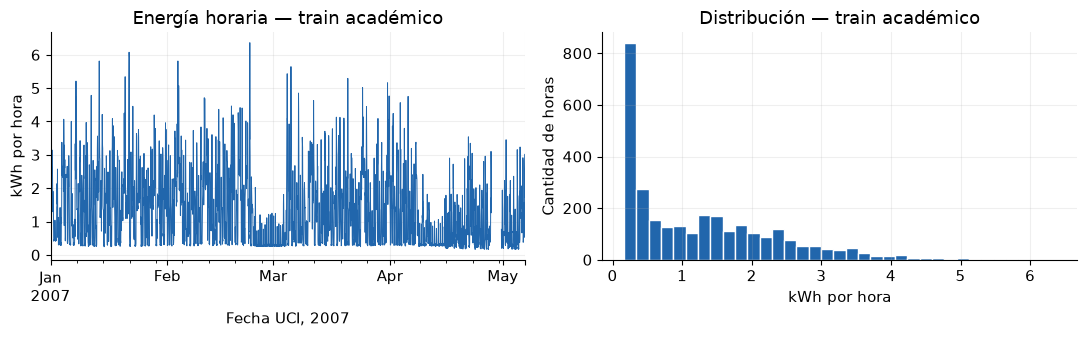

In [4]:
display(train[["load_kwh", "observed_minutes", "imputed_minutes"]].describe().round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
train.load_kwh.plot(ax=axes[0], color="#2166ac", lw=.7, title="Energía horaria — train académico")
axes[0].set(xlabel="Fecha UCI, 2007", ylabel="kWh por hora")
axes[1].hist(train.load_kwh.dropna(), bins=35, color="#2166ac", edgecolor="white")
axes[1].set(title="Distribución — train académico", xlabel="kWh por hora", ylabel="Cantidad de horas")
fig.tight_layout(); plt.show()

### Ventanas 168 → 24 y normalización
Cada entrada termina antes del origen; los 24 objetivos permanecen en su
partición y deben estar observados. Validación/test pueden usar **pasado ya
disponible** de particiones anteriores. Nunca se unen horas separadas por huecos.

Las siguientes funciones se extraen del núcleo del proyecto. El normalizador
se ajusta una vez con horas observadas de train: estandariza entradas y divide
objetivos por la desviación, sin centrarlos. Así una salida `softplus` mantiene
consumo no negativo. Las métricas finales revierten esa transformación a kWh.

In [5]:
def validate_hourly(frame: pd.DataFrame) -> None:
    required = {"load_kwh", "is_observed_complete"}
    if not required <= set(frame.columns) or frame.empty:
        raise ValueError("Nonempty hourly data with load_kwh/is_observed_complete required")
    index = frame.index
    if not isinstance(index, pd.DatetimeIndex) or index.hasnans or index.has_duplicates:
        raise ValueError("Valid unique datetime index required")
    if not index.is_monotonic_increasing or not (index == index.floor("h")).all():
        raise ValueError("Hourly aligned, chronological timestamps required")
    if frame["is_observed_complete"].isna().any() or not frame["is_observed_complete"].isin([True, False]).all():
        raise ValueError("is_observed_complete must contain actual booleans")
    values = frame["load_kwh"].to_numpy(dtype=float)
    if np.isinf(values).any() or (values < 0).any():
        raise ValueError("Demand must be nonnegative, finite or missing")
    if (frame["is_observed_complete"].to_numpy(dtype=bool) & ~np.isfinite(values)).any():
        raise ValueError("Observed-complete targets cannot have unknown energy")

@dataclass(frozen=True)
class WindowSet:
    x: np.ndarray
    y: np.ndarray
    origins: pd.DatetimeIndex
    report: dict

def make_windows(partition: pd.DataFrame, *, history: pd.DataFrame | None = None,
                 lookback: int = 168, horizon: int = 24, stride: int = 1) -> WindowSet:
    for name, value in (("lookback", lookback), ("horizon", horizon), ("stride", stride)):
        if type(value) is not int or value <= 0:
            raise ValueError(f"{name} must be a positive integer")
    validate_hourly(partition)
    if history is not None:
        validate_hourly(history)
        if history.index.max() >= partition.index.min():
            raise ValueError("History must strictly precede the target partition")
        if str(history.index.tz) != str(partition.index.tz):
            raise ValueError("History and target timezones must agree")
        combined = pd.concat([history.tail(lookback), partition])
    else:
        combined = partition
    # Reindex, never drop missing hours and accidentally join nonadjacent times.
    grid = pd.date_range(combined.index.min(), partition.index.max(), freq="h", name="timestamp")
    regular = combined.reindex(grid)
    values = regular.load_kwh.to_numpy(dtype=float)
    observed = regular.is_observed_complete.fillna(False).to_numpy(dtype=bool)
    start = grid.get_loc(partition.index.min())
    counts = {"candidates": 0, "insufficient_history": 0, "unknown_inputs": 0,
              "unknown_targets": 0, "accepted": 0}
    xs, ys, origins = [], [], []
    for origin in range(start, len(grid) - horizon + 1, stride):
        counts["candidates"] += 1
        if origin < lookback:
            counts["insufficient_history"] += 1
            continue
        x = values[origin - lookback:origin]
        y = values[origin:origin + horizon]
        if not np.isfinite(x).all():
            counts["unknown_inputs"] += 1
            continue
        if not observed[origin:origin + horizon].all() or not np.isfinite(y).all():
            counts["unknown_targets"] += 1
            continue
        xs.append(x)
        ys.append(y)
        origins.append(grid[origin])
    counts["accepted"] = len(xs)
    counts.update({"lookback": lookback, "horizon": horizon, "stride": stride,
                   "partition_start": partition.index.min().isoformat(),
                   "partition_end": partition.index.max().isoformat(),
                   "input_policy": "all hours known; causal phase1 imputations allowed",
                   "target_policy": "all hours observed-complete; no imputed targets"})
    return WindowSet(np.asarray(xs, dtype=np.float32).reshape(-1, lookback),
                     np.asarray(ys, dtype=np.float32).reshape(-1, horizon),
                     pd.DatetimeIndex(origins, name="origin"), counts)

@dataclass(frozen=True)
class DemandNormalizer:
    mean_kwh: float
    scale_kwh: float
    fitted_hours: int
    fitted_start: str
    fitted_end: str

    def __post_init__(self):
        if not math.isfinite(self.mean_kwh) or not math.isfinite(self.scale_kwh) or self.scale_kwh <= 0:
            raise ValueError('Invalid normalization parameters')
        if self.fitted_hours < 1:
            raise ValueError('Normalizer requires observed training hours')

    @classmethod
    def fit(cls, train: pd.DataFrame) -> 'DemandNormalizer':
        validate_hourly(train)
        observed = train.loc[train.is_observed_complete.astype(bool), 'load_kwh']
        if observed.empty:
            raise ValueError('No observed training values for normalization')
        values = observed.to_numpy(dtype=np.float64)
        std = float(values.std())
        return cls(float(values.mean()), std if std > 1e-06 else 1.0, len(values), observed.index.min().isoformat(), observed.index.max().isoformat())

    def inputs(self, values: np.ndarray) -> np.ndarray:
        return ((np.asarray(values) - self.mean_kwh) / self.scale_kwh).astype(np.float32)

    def targets(self, values: np.ndarray) -> np.ndarray:
        return (np.asarray(values) / self.scale_kwh).astype(np.float32)

    def inverse_targets(self, values: np.ndarray) -> np.ndarray:
        return np.asarray(values, dtype=np.float64) * self.scale_kwh

In [6]:
# Stride de train reducido; validación/test no solapan sus 24 objetivos.
w_train = make_windows(train, stride=3)
w_val = make_windows(validation, history=train, stride=24)
w_test = make_windows(academic_test, history=pd.concat([train, validation]), stride=24)
normalizer = DemandNormalizer.fit(train)
assert normalizer.fitted_end <= str(train.index.max().isoformat())
assert w_val.origins.min() >= validation.index.min() and w_test.origins.min() >= academic_test.index.min()
assert all(len(w.x) > 0 for w in (w_train, w_val, w_test))
display(pd.DataFrame([w.report for w in (w_train, w_val, w_test)], index=["train", "validación", "test académico"])
        [["candidates", "accepted", "unknown_inputs", "unknown_targets"]])

,candidates,accepted,unknown_inputs,unknown_targets
train,1001,841,64,40
validación,27,25,1,1
test académico,28,17,7,4


## 4. MLP: aprender por optimización de pesos
Una **red multicapa (MLP)** combina neuronas densas: cada capa calcula una
transformación de entradas y una activación no lineal. Usamos 168 valores,
capas ocultas de **64 y 32** neuronas ReLU y 24 salidas no negativas.

La pérdida **MSE** es el promedio de errores al cuadrado. La retropropagación
calcula su gradiente respecto a los pesos; **Adam** adapta los pasos usando
estimaciones de primer y segundo momento de esos gradientes. EarlyStopping
restaura los pesos de menor pérdida en **validación**, sin consultar test.
Fijamos una semilla, Adam 0,001, máximo 25 épocas y paciencia 4; no hacemos
búsqueda de arquitecturas. La versión académica no incorpora calendario ni
MSE ponderada, para aislar los conceptos esenciales.

keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Parámetros: 13,688; épocas: 16; CPU: 2.60 s


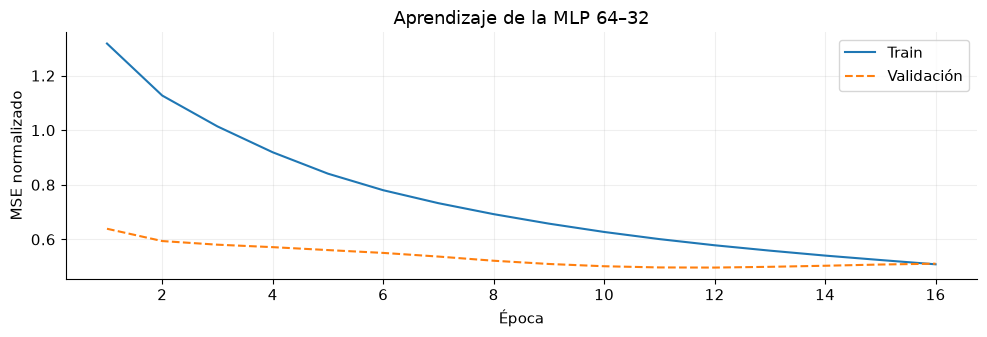

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(168,)),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(24, activation="softplus"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss="mse",
              metrics=[tf.keras.metrics.MeanAbsoluteError(name="mae"),
                       tf.keras.metrics.RootMeanSquaredError(name="rmse")])

def batches(windows):
    ds = tf.data.Dataset.from_tensor_slices((normalizer.inputs(windows.x), normalizer.targets(windows.y))).batch(64)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return ds.with_options(options)

started = perf_counter()
history = model.fit(batches(w_train), validation_data=batches(w_val), epochs=25, verbose=0,
                    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
training_seconds = perf_counter() - started
print(f"Parámetros: {model.count_params():,}; épocas: {len(history.history['loss'])}; CPU: {training_seconds:.2f} s")
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(history.history['loss'])+1), history.history["loss"], label="Train")
ax.plot(np.arange(1, len(history.history['loss'])+1), history.history["val_loss"], label="Validación", ls="--")
ax.set(xlabel="Época", ylabel="MSE normalizado", title="Aprendizaje de la MLP 64–32")
ax.legend(); fig.tight_layout(); plt.show()

### Evaluación: MLP frente a persistencia de 24 horas
Persistencia repite el último día observado. MAE promedia errores absolutos;
RMSE penaliza más los grandes errores. Ambos se calculan en **kWh**, sobre
exactamente los mismos objetivos. Sólo ahora se evalúa el test académico,
una vez congelado el modelo; no se elige ninguna configuración con él.

,Partición,Modelo,MAE kWh,RMSE kWh
0,Validación,MLP,0.5784,0.7583
1,Validación,Persistencia 24 h,0.6458,0.9535
2,Test académico,MLP,0.5965,0.7687
3,Test académico,Persistencia 24 h,0.6205,0.9700


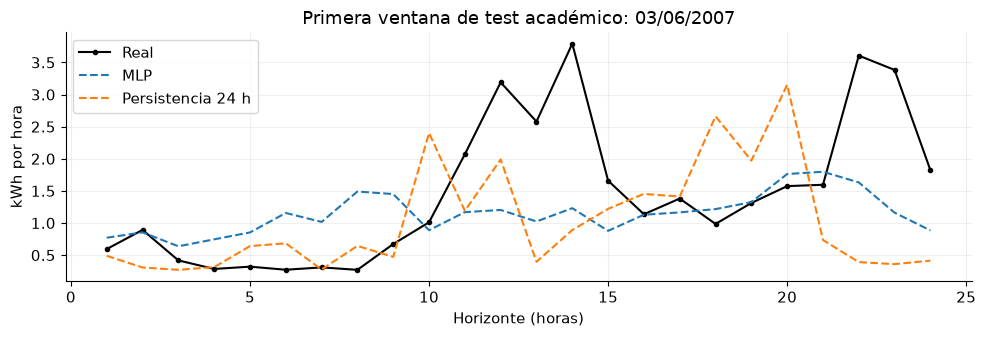

In [8]:
def seasonal_persistence(x: np.ndarray, *, lag: int, horizon: int = 24) -> np.ndarray:
    x = np.asarray(x)
    if x.ndim != 2 or type(lag) is not int or type(horizon) is not int:
        raise ValueError("Expected a 2D history and integer lag/horizon")
    if not 0 < horizon <= lag <= x.shape[1] or not np.isfinite(x).all():
        raise ValueError("Require finite history and horizon <= lag <= lookback")
    return x[:, x.shape[1] - lag + np.arange(horizon)].copy()


def physical_metrics(actual, predicted):
    assert actual.shape == predicted.shape and np.isfinite(predicted).all()
    error = np.asarray(predicted, float) - np.asarray(actual, float)
    return {"MAE kWh": float(np.mean(np.abs(error))), "RMSE kWh": float(np.sqrt(np.mean(error**2)))}

metrics_rows, predictions = [], {}
for name, windows in [("Validación", w_val), ("Test académico", w_test)]:
    predicted = normalizer.inverse_targets(model(normalizer.inputs(windows.x), training=False).numpy())
    baseline = seasonal_persistence(windows.x, lag=24)
    predictions[name] = {"MLP": predicted, "Persistencia 24 h": baseline}
    for label, values in predictions[name].items():
        metrics_rows.append({"Partición": name, "Modelo": label, **physical_metrics(windows.y, values)})
predictive_metrics = pd.DataFrame(metrics_rows)
display(predictive_metrics.round(4))
# Gráfico fijado: primera ventana aceptada de test académico, nunca la mejor.
fig, ax = plt.subplots()
ax.plot(range(1, 25), w_test.y[0], color="black", label="Real", marker=".")
for label, values in predictions["Test académico"].items():
    ax.plot(range(1, 25), values[0], label=label, ls="--")
ax.set(xlabel="Horizonte (horas)", ylabel="kWh por hora",
       title=f"Primera ventana de test académico: {w_test.origins[0]:%d/%m/%Y}")
ax.legend(); fig.tight_layout(); plt.show()

## 5. Espacio de estados, física y búsqueda A*
El estado es **(hora, energía almacenada)**. Elegir otro nivel de batería
representa cargar, descargar o mantener. Se limita capacidad, reserva 20 %,
potencia 2,5 kW y eficiencias 95 %. La grilla es 0,5 kWh; el simulador conserva
energía continua y el SOC no se redondea al ejecutar. Horizonte: 24 horas.

En el bus AC: `solar + red + descarga = consumo servido + carga + recorte`.
En batería: `E_siguiente = E + eta_c*carga - descarga/eta_d`.
El costo de arista es `importación_kWh * tarifa_SIM_por_kWh`. No hay
exportación, cortes ni cargas críticas en esta versión reducida.

El simulador y los métodos físicos siguientes son extraídos del MVP,
no copiados como otra implementación independiente. Sólo se simplifican los
contenedores de configuración y la construcción del grafo, conservando
fronteras físicas y energía inicial exacta. El generador registra sus hashes.

In [9]:
HomeConfig = SimpleNamespace  # Contenedor académico, sin archivos de configuración.
EPS = 1e-9

@dataclass(frozen=True)
class EnergyState:
    step: int
    stored_kwh: float

@dataclass(frozen=True)
class EnergyAction:
    charge_kw: float = 0.0
    discharge_kw: float = 0.0

@dataclass(frozen=True)
class StepResult:
    state: EnergyState
    grid_import_kwh: float
    grid_export_kwh: float
    curtailed_kwh: float
    cost: float
    demand_kwh: float = 0.0
    solar_kwh: float = 0.0
    served_kwh: float = 0.0
    unserved_kwh: float = 0.0
    charge_kwh: float = 0.0  # AC bus, not stored energy.
    discharge_kwh: float = 0.0  # AC bus, after discharge losses.
    pv_direct_kwh: float = 0.0
    pv_charge_kwh: float = 0.0
    grid_charge_kwh: float = 0.0
    conversion_loss_kwh: float = 0.0
    balance_residual_kwh: float = 0.0
    storage_residual_kwh: float = 0.0
    action_adjusted: bool = False
    constraint_violations: int = 0

In [10]:
def finite_nonnegative(value, name):
    if not math.isfinite(value) or value < 0:
        raise ValueError(f"{name} must be finite and nonnegative")

class PhysicalSimulator:
    """No simultaneous charge/discharge, no battery export, unlimited grid when up.

    `repair=False` rejects infeasible commands (used inside search). `repair=True`
    is the realization controller: cap commands, serve load first, and never
    borrow energy from below reserve, even during an outage. It does not create
    an unrequested discharge to hide forecast errors.
    """

    def step(self, state: EnergyState, action: EnergyAction, demand_kwh: float,
             solar_kwh: float, config: HomeConfig, *, grid_available: bool = True,
             repair: bool = False, import_price: float | None = None,
             allow_export: bool = False) -> StepResult:
        if type(state.step) is not int or state.step < 0:
            raise ValueError("State step must be a nonnegative integer")
        if type(grid_available) is not bool or type(allow_export) is not bool:
            raise ValueError("Grid/export availability must be boolean")
        for name, value in (("demand", demand_kwh), ("solar", solar_kwh),
                            ("charge_kw", action.charge_kw), ("discharge_kw", action.discharge_kw)):
            finite_nonnegative(value, name)
        if action.charge_kw > 0 and action.discharge_kw > 0:
            raise ValueError("Simultaneous battery charge/discharge is forbidden")
        capacity, reserve, dt = config.battery_capacity_kwh, config.min_soc * config.battery_capacity_kwh, config.step_hours
        stored = state.stored_kwh
        if not math.isfinite(stored) or stored < reserve - EPS or stored > capacity + EPS:
            raise ValueError("Stored energy outside capacity/reserve")
        # Only numerical boundary tolerance; no SOC discretization/rounding here.
        stored = min(capacity, max(reserve, stored))
        price = config.import_prices[state.step % config.horizon_steps] if import_price is None else import_price
        finite_nonnegative(price, "import price")
        requested_charge = action.charge_kw * dt
        requested_discharge = action.discharge_kw * dt
        direct = min(demand_kwh, solar_kwh)
        surplus = solar_kwh - direct
        deficit = demand_kwh - direct
        charge_limit = min(config.max_charge_kw * dt, (capacity - stored) / config.charge_efficiency)
        if not grid_available:
            charge_limit = min(charge_limit, surplus)
        discharge_limit = min(config.max_discharge_kw * dt,
                              max(0., stored - reserve) * config.discharge_efficiency, deficit)
        charge = min(requested_charge, max(0., charge_limit))
        discharge = min(requested_discharge, max(0., discharge_limit))
        adjusted = abs(charge - requested_charge) > EPS or abs(discharge - requested_discharge) > EPS
        if adjusted and not repair:
            raise ValueError("Requested action exceeds power, storage, load or grid availability")
        pv_charge = min(surplus, charge)
        grid_charge = charge - pv_charge
        grid_load = max(0., deficit - discharge) if grid_available else 0.
        imported = grid_load + grid_charge
        unserved = max(0., deficit - discharge - grid_load)
        remainder = max(0., surplus - pv_charge)
        exported = remainder if allow_export and grid_available else 0.
        curtailed = remainder - exported
        next_stored = stored + config.charge_efficiency * charge - discharge / config.discharge_efficiency
        charge_loss = charge * (1 - config.charge_efficiency)
        discharge_loss = discharge * (1 / config.discharge_efficiency - 1)
        loss = charge_loss + discharge_loss
        served = demand_kwh - unserved
        ac_residual = solar_kwh + imported + discharge - (served + charge + exported + curtailed)
        storage_residual = stored + solar_kwh + imported - (next_stored + served + exported + curtailed + loss)
        violations = sum((next_stored < reserve - EPS, next_stored > capacity + EPS,
                          charge > config.max_charge_kw * dt + EPS,
                          discharge > config.max_discharge_kw * dt + EPS,
                          abs(ac_residual) > EPS, abs(storage_residual) > EPS,
                          charge > EPS and discharge > EPS, imported > EPS and exported > EPS))
        if violations:
            raise ArithmeticError("Physical energy invariant failed")
        next_stored = min(capacity, max(reserve, next_stored))  # Floating-point boundary noise only.
        cost = imported * price - exported * config.export_prices[state.step % config.horizon_steps]
        return StepResult(EnergyState(state.step + 1, next_stored), imported, exported, curtailed, cost,
                          demand_kwh, solar_kwh, served, unserved, charge, discharge, direct,
                          pv_charge, grid_charge, loss, ac_residual, storage_residual, adjusted, violations)

class SelfConsumptionStrategy:
    """Ideal instantaneous feedback represented by constant within-hour averages.

    Uses only present imbalance, never forecasts, future tariffs or future load.
    Requests PV-surplus charging or deficit discharging; the same realization
    controller enforces all limits. It never intentionally charges from grid.
    """

    def action(self, demand_kwh, solar_kwh, config):
        finite_nonnegative(demand_kwh, "demand")
        finite_nonnegative(solar_kwh, "solar")
        if solar_kwh > demand_kwh:
            return EnergyAction(charge_kw=(solar_kwh - demand_kwh) / config.step_hours)
        return EnergyAction(discharge_kw=(demand_kwh - solar_kwh) / config.step_hours)

### El algoritmo de búsqueda
A* expande el estado de menor **f = g + h**: costo acumulado más una cota
optimista del costo restante. La heurística ignora límites y cronología,
usa todo el solar futuro de forma optimista y compra al menor precio futuro;
por eso no sobreestima el óptimo. Con **h=0**, A* equivale a costo uniforme.
Validaremos ambas opciones contra enumeración en un problema pequeño.

La cola prioritaria y la reapertura de estados son las del núcleo original.
La garantía se refiere al grafo discretizado y al pronóstico utilizado;
no garantiza el mejor resultado con consumo real desconocido.

In [11]:
class ScalarArithmetic:
    zero = 0.

    @staticmethod
    def add(a, b):
        return a + b

    @staticmethod
    def better(a, b):
        return b is None or a < b - 1e-12  # Original scalar reference tolerance.

    @staticmethod
    def stale(a, b):
        return a > b + 1e-12

    @staticmethod
    def valid(value):
        return math.isfinite(value) and value >= 0

@dataclass(frozen=True)
class SearchResult:
    actions: tuple
    states: tuple
    value: object
    expanded_nodes: int
    generated_nodes: int
    elapsed_seconds: float

def astar_search(problem, initial_state, settings, limit_error, arithmetic=None):
    """Reopen improved labels. Finite acyclic time graph; first popped goal wins.

    Scalar comparisons retain the reference numerical tolerance. Tuple labels
    are ordered exactly and never traded via a finite scalar penalty.
    """
    ops = arithmetic or ScalarArithmetic()
    started, serial = perf_counter(), count()
    estimate = problem.heuristic(initial_state)
    if not ops.valid(estimate):
        raise ValueError("Heuristic must be finite, nonnegative and match objective units")
    frontier = [(estimate, -initial_state.step, next(serial), ops.zero, initial_state)]
    distance, parents = {initial_state: ops.zero}, {}
    expanded, generated = 0, 1
    while frontier:
        if expanded >= settings.max_expanded or perf_counter() - started > settings.max_seconds:
            raise limit_error("Search resource limit reached; optimality not established")
        _, _, _, cost, state = heapq.heappop(frontier)
        if ops.stale(cost, distance[state]):
            continue
        if problem.is_goal(state):
            actions, states = [], [state]
            while state != initial_state:
                previous, action = parents[state]
                actions.append(action)
                states.append(previous)
                state = previous
            return SearchResult(tuple(reversed(actions)), tuple(reversed(states)), cost,
                                expanded, generated, perf_counter() - started)
        expanded += 1
        for action, successor, edge in problem.successors(state):
            if not ops.valid(edge):
                raise ValueError("Search edge must be finite, nonnegative and match objective units")
            candidate = ops.add(cost, edge)
            if ops.better(candidate, distance.get(successor)):
                distance[successor] = candidate
                parents[successor] = (state, action)
                estimate = problem.heuristic(successor)
                if not ops.valid(estimate):
                    raise ValueError("Heuristic must be finite, nonnegative and match objective units")
                heapq.heappush(frontier, (ops.add(candidate, estimate), -successor.step,
                                         next(serial), candidate, successor))
                generated += 1
    raise ValueError("No feasible plan reaches the terminal requirement")

In [12]:
class ProblemaBateria:
    """Adaptador horario reducido; aristas, heurística y metas del núcleo."""
    def __init__(self, inputs, initial, settings):
        self.inputs, self.initial, self.settings = inputs, initial, settings
        c = inputs.config
        self.horizon = c.horizon_steps
        assert len(inputs.forecast.demand_kwh) == len(inputs.solar_kwh) == self.horizon
        assert initial.step == 0 and all(v >= 0 for v in (*inputs.forecast.demand_kwh, *inputs.solar_kwh))
        self.reserve = c.min_soc * c.battery_capacity_kwh
        self.terminal = self.reserve
        steps = math.floor((c.battery_capacity_kwh - self.reserve) / settings.storage_step_kwh)
        self.levels = tuple(sorted(set([self.reserve + i*settings.storage_step_kwh for i in range(steps+1)]
                                      + [c.battery_capacity_kwh, initial.stored_kwh, self.terminal])))
        self.simulator = PhysicalSimulator()

    def physical_successors(self, state):
        """Shared graph edges and physical ledgers, independent of objective."""
        if state.step >= self.horizon:
            return []
        c, t = self.inputs.config, state.step
        successors = []
        for target in self.levels:
            delta = target - state.stored_kwh
            action = (EnergyAction(charge_kw=delta / (c.charge_efficiency * c.step_hours)) if delta > 0
                      else EnergyAction(discharge_kw=-delta * c.discharge_efficiency / c.step_hours))
            try:
                result = self.simulator.step(state, action, self.inputs.forecast.demand_kwh[t],
                                             self.inputs.solar_kwh[t], c)
            except ValueError:
                continue  # Infeasible physical edge is absent, not rounded/clipped into existence.
            if abs(result.state.stored_kwh - target) > EPS or result.cost < -EPS:
                raise ArithmeticError("Invalid state-grid transition or negative edge")
            successors.append((action, EnergyState(t + 1, target), result))
        return successors

    def successors(self, state):
        return [(action, successor, result.cost)
                for action, successor, result in self.physical_successors(state)]

    def heuristic(self, state):
        if self.settings.heuristic == "zero" or state.step == self.horizon:
            return 0.
        return min(self.inputs.config.import_prices[state.step:]) * self.grid_lower_bound(state)

    def grid_lower_bound(self, state):
        """Continuous optimistic AC import bound; ignores timing/power/terminal."""
        if state.step == self.horizon:
            return 0.
        c = self.inputs.config
        demand = self.inputs.forecast.demand_kwh[state.step:]
        solar = self.inputs.solar_kwh[state.step:]
        deficits = sum(max(d - s, 0.) for d, s in zip(demand, solar))
        surplus = sum(max(s - d, 0.) for d, s in zip(demand, solar))
        usable = (state.stored_kwh - self.reserve) * c.discharge_efficiency
        optimistic_stored_solar = surplus * c.charge_efficiency * c.discharge_efficiency
        grid_lower_bound = max(0., deficits - usable - optimistic_stored_solar)
        # Ignores capacity, power, chronology and terminal replenishment, and buys
        # all remaining required energy at its cheapest tariff. Thus optimistic.
        return grid_lower_bound

    def is_goal(self, state):
        return state.step == self.horizon and state.stored_kwh >= self.terminal - EPS

## 6. Solar independiente y ejemplo fijado previamente
PVGIS 6, JRC/Comisión Europea, ERA5: **Córdoba −31,4201 / −64,1888**, 3 kWp,
inclinación 30° hacia norte, eficiencia del sistema 0,86 ya aplicada.
Usamos las primeras 48 horas del perfil modelado 15–16/01/2023, con timestamps
UTC y locales conservados. El perfil pequeño se incluye en este notebook;
no depende de GitHub ni de una API cambiante al ejecutar.

Lo alineamos por hora ordinal con un día UCI: **no son mediciones
sincronizadas**, ni de la misma vivienda/época. El solar futuro es idealizado.
No repetimos artificialmente un mismo día. La energía solar se mide aquí en
kWh por intervalo; no se vuelve a aplicar el rendimiento PVGIS.

Episodio: **primera ventana de test académico aceptada a medianoche**.
Ocurre después de toda la validación usada por EarlyStopping: los pesos
seleccionados ya están congelados antes del episodio. Se fija por orden y
completitud, antes de comparar costos; no se selecciona una estrategia con
los resultados de test. Ejecutamos 24 h,
replanificando cada hora con 168 observaciones previas. La previsión afecta
el déficit estimado, la importación y los costos de las aristas de A*.

In [13]:
SOLAR_CSV = 'scenario_hour,source_utc,source_local,solar_kwh\n0,2023-01-15 03:00:00+00:00,2023-01-15 00:00:00-03:00,0.000000000\n1,2023-01-15 04:00:00+00:00,2023-01-15 01:00:00-03:00,0.000000000\n2,2023-01-15 05:00:00+00:00,2023-01-15 02:00:00-03:00,0.000000000\n3,2023-01-15 06:00:00+00:00,2023-01-15 03:00:00-03:00,0.000000000\n4,2023-01-15 07:00:00+00:00,2023-01-15 04:00:00-03:00,0.000000000\n5,2023-01-15 08:00:00+00:00,2023-01-15 05:00:00-03:00,0.000000000\n6,2023-01-15 09:00:00+00:00,2023-01-15 06:00:00-03:00,0.000000000\n7,2023-01-15 10:00:00+00:00,2023-01-15 07:00:00-03:00,0.009967680\n8,2023-01-15 11:00:00+00:00,2023-01-15 08:00:00-03:00,0.181320650\n9,2023-01-15 12:00:00+00:00,2023-01-15 09:00:00-03:00,0.698375000\n10,2023-01-15 13:00:00+00:00,2023-01-15 10:00:00-03:00,1.283549800\n11,2023-01-15 14:00:00+00:00,2023-01-15 11:00:00-03:00,1.786596900\n12,2023-01-15 15:00:00+00:00,2023-01-15 12:00:00-03:00,1.968858200\n13,2023-01-15 16:00:00+00:00,2023-01-15 13:00:00-03:00,1.777477700\n14,2023-01-15 17:00:00+00:00,2023-01-15 14:00:00-03:00,1.940756600\n15,2023-01-15 18:00:00+00:00,2023-01-15 15:00:00-03:00,1.625729200\n16,2023-01-15 19:00:00+00:00,2023-01-15 16:00:00-03:00,1.639921500\n17,2023-01-15 20:00:00+00:00,2023-01-15 17:00:00-03:00,1.281872100\n18,2023-01-15 21:00:00+00:00,2023-01-15 18:00:00-03:00,0.780629330\n19,2023-01-15 22:00:00+00:00,2023-01-15 19:00:00-03:00,0.210058290\n20,2023-01-15 23:00:00+00:00,2023-01-15 20:00:00-03:00,0.000790950\n21,2023-01-16 00:00:00+00:00,2023-01-15 21:00:00-03:00,0.000000000\n22,2023-01-16 01:00:00+00:00,2023-01-15 22:00:00-03:00,0.000000000\n23,2023-01-16 02:00:00+00:00,2023-01-15 23:00:00-03:00,0.000000000\n24,2023-01-16 03:00:00+00:00,2023-01-16 00:00:00-03:00,0.000000000\n25,2023-01-16 04:00:00+00:00,2023-01-16 01:00:00-03:00,0.000000000\n26,2023-01-16 05:00:00+00:00,2023-01-16 02:00:00-03:00,0.000000000\n27,2023-01-16 06:00:00+00:00,2023-01-16 03:00:00-03:00,0.000000000\n28,2023-01-16 07:00:00+00:00,2023-01-16 04:00:00-03:00,0.000000000\n29,2023-01-16 08:00:00+00:00,2023-01-16 05:00:00-03:00,0.000000000\n30,2023-01-16 09:00:00+00:00,2023-01-16 06:00:00-03:00,0.000000000\n31,2023-01-16 10:00:00+00:00,2023-01-16 07:00:00-03:00,0.008733644\n32,2023-01-16 11:00:00+00:00,2023-01-16 08:00:00-03:00,0.171272020\n33,2023-01-16 12:00:00+00:00,2023-01-16 09:00:00-03:00,0.677520100\n34,2023-01-16 13:00:00+00:00,2023-01-16 10:00:00-03:00,1.230965100\n35,2023-01-16 14:00:00+00:00,2023-01-16 11:00:00-03:00,1.781469400\n36,2023-01-16 15:00:00+00:00,2023-01-16 12:00:00-03:00,2.152448200\n37,2023-01-16 16:00:00+00:00,2023-01-16 13:00:00-03:00,2.357387000\n38,2023-01-16 17:00:00+00:00,2023-01-16 14:00:00-03:00,2.418394000\n39,2023-01-16 18:00:00+00:00,2023-01-16 15:00:00-03:00,2.266503700\n40,2023-01-16 19:00:00+00:00,2023-01-16 16:00:00-03:00,2.048599000\n41,2023-01-16 20:00:00+00:00,2023-01-16 17:00:00-03:00,1.445640500\n42,2023-01-16 21:00:00+00:00,2023-01-16 18:00:00-03:00,0.876026250\n43,2023-01-16 22:00:00+00:00,2023-01-16 19:00:00-03:00,0.266280820\n44,2023-01-16 23:00:00+00:00,2023-01-16 20:00:00-03:00,0.001178625\n45,2023-01-17 00:00:00+00:00,2023-01-16 21:00:00-03:00,0.000000000\n46,2023-01-17 01:00:00+00:00,2023-01-16 22:00:00-03:00,0.000000000\n47,2023-01-17 02:00:00+00:00,2023-01-16 23:00:00-03:00,0.000000000\n'
assert digest(SOLAR_CSV.encode()) == 'eabc7acba56a8d790cad67c0b5298ec032fc9e3bb110667a6ac0d4d35b4fd1fa'

solar_frame = pd.read_csv(io.StringIO(SOLAR_CSV))
solar = solar_frame.solar_kwh.to_numpy(float)
assert len(solar) == 48 and (solar >= 0).all()
origin = w_test.origins[0]
assert origin.hour == 0
assert validation.index.max() < origin  # Selección de pesos anterior a la operación.
episode_times = pd.date_range(origin, periods=24, freq="h")
actual_demand = hourly.reindex(episode_times).load_kwh.to_numpy(float)
assert hourly.reindex(episode_times).is_observed_complete.all()
past_inputs = []
for now in episode_times:
    past = hourly.loc[hourly.index < now].tail(168)
    assert len(past) == 168 and past.index.max() < now and past.load_kwh.notna().all()
    past_inputs.append(past.load_kwh.to_numpy(float))
past_inputs = np.asarray(past_inputs)
# Procesar las 24 entradas juntas ahorra CPU; cada fila sólo contiene su pasado.
causal_forecasts = {
    "A* persistencia": seasonal_persistence(past_inputs, lag=24),
    "A* MLP": normalizer.inverse_targets(model(normalizer.inputs(past_inputs), training=False).numpy()),
}
prices = np.array([.08 if h < 7 else .38 if 18 <= h < 23 else .15 for h in range(24)])
print("Episodio UCI:", origin, "— 24 h; solar independiente:", solar_frame.source_local.iloc[0])

Episodio UCI: 2007-06-03 00:00:00 — 24 h; solar independiente: 2023-01-15 00:00:00-03:00


In [14]:
def home_config(prices, capacity=5., initial_soc=.5):
    return SimpleNamespace(battery_capacity_kwh=capacity, min_soc=.2, initial_soc=initial_soc,
        max_charge_kw=2.5, max_discharge_kw=2.5, charge_efficiency=.95, discharge_efficiency=.95,
        step_hours=1., horizon_steps=len(prices), import_prices=tuple(prices), export_prices=(0.,)*len(prices))

def plan(demand, sun, prices, energy, heuristic="relaxed", capacity=5.):
    home = home_config(prices, capacity)
    settings = SimpleNamespace(storage_step_kwh=.5, heuristic=heuristic, max_expanded=10000, max_seconds=10.)
    inputs = SimpleNamespace(config=home, solar_kwh=tuple(sun), forecast=SimpleNamespace(demand_kwh=tuple(demand)))
    problem = ProblemaBateria(inputs, EnergyState(0, energy), settings)
    result = astar_search(problem, problem.initial, settings, RuntimeError)
    return result, problem

def replay(label):
    home = home_config(prices)
    state = EnergyState(0, home.initial_soc * home.battery_capacity_kwh)
    rows = []
    for t in range(24):
        if label == "Reactivo":
            action = SelfConsumptionStrategy().action(actual_demand[t], solar[t], home)
            nodes = 0
        else:
            forecast = causal_forecasts[label][t]  # No demanda futura realizada.
            result, _ = plan(forecast, solar[t:t+24], np.roll(prices, -t), state.stored_kwh)
            action, nodes = result.actions[0], result.expanded_nodes
        # Sólo la primera acción se ejecuta con la demanda realmente observada.
        step = PhysicalSimulator().step(state, action, actual_demand[t], solar[t], home,
                                         repair=True, import_price=prices[t])
        rows.append({**asdict(step), "initial_kwh": state.stored_kwh,
                     "stored_kwh": step.state.stored_kwh, "nodes": nodes})
        state = step.state
    ledger = pd.DataFrame(rows)
    assert ledger.constraint_violations.sum() == 0
    assert ledger.balance_residual_kwh.abs().max() < 1e-8 and ledger.storage_residual_kwh.abs().max() < 1e-8
    assert ledger.stored_kwh.between(1-1e-9, 5+1e-9).all() and ledger.unserved_kwh.sum() < 1e-9
    assert np.allclose(ledger.initial_kwh.iloc[1:], ledger.stored_kwh.iloc[:-1])
    initial, final = ledger.initial_kwh.iloc[0], ledger.stored_kwh.iloc[-1]
    gross = ledger.cost.sum()
    return ledger, {"Estrategia": label, "Costo bruto SIM": gross,
        "Costo ajustado SIM": gross + .1425*(initial-final), "Red kWh": ledger.grid_import_kwh.sum(),
        "SOC inicial %": 100*initial/5, "SOC final %": 100*final/5,
        "Violaciones": int(ledger.constraint_violations.sum()), "Nodos": int(ledger.nodes.sum())}

ledgers, energy_rows = {}, []
for label in ("Reactivo", "A* persistencia", "A* MLP"):
    ledgers[label], row = replay(label)
    energy_rows.append(row)
energy_metrics = pd.DataFrame(energy_rows).set_index("Estrategia")
display(energy_metrics.round(4))

,Costo bruto SIM,Costo ajustado SIM,Red kWh,SOC inicial %,SOC final %,Violaciones,Nodos
Estrategia,,,,,,,
Reactivo,4.8161,5.0299,18.6521,50.0,20.0,0,0
A* persistencia,4.7397,4.7397,21.3515,50.0,50.0,0,3349
A* MLP,4.2329,4.4466,19.9119,50.0,20.0,0,3475


### Comparación bajo condiciones idénticas
Todas las estrategias reciben el mismo consumo realizado, solar, tarifa,
batería y SOC inicial. El control físico común recorta comandos incompatibles
con el consumo realizado; no crea energía ni descargas no solicitadas.
El reactivo usa sólo el desequilibrio presente. Los A* reciben sus respectivos
pronósticos, ejecutan una acción y vuelven a planificar al observar la hora.

Mostramos costo bruto y saldo de batería. El costo ajustado añade
`0,1425*(E_inicial−E_final)` SIM, valoración ilustrativa fija de energía
almacenada; **no es una factura**. Así no se atribuye a ahorro retirar
más energía de la batería. Esta comparación de un día no es un estudio anual.

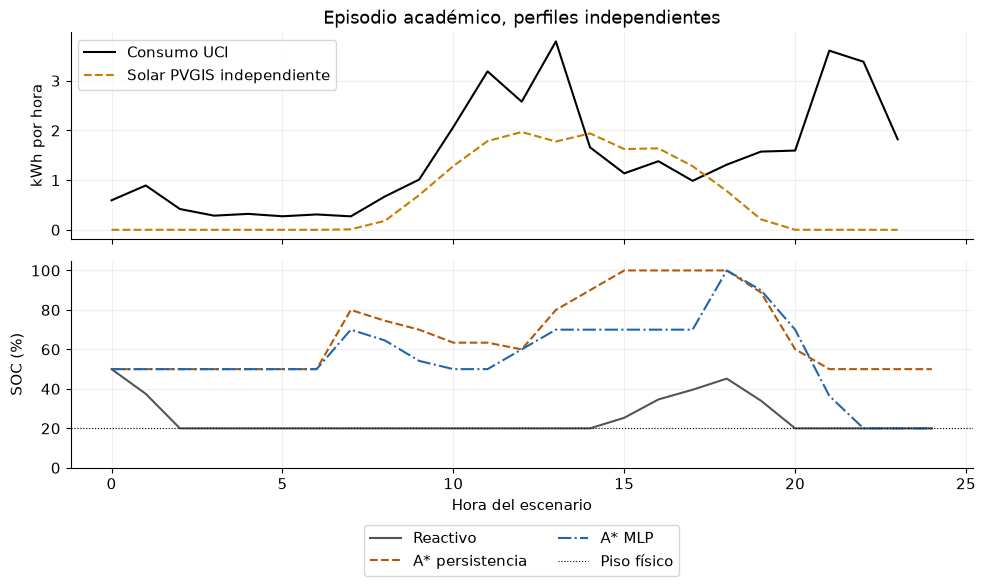

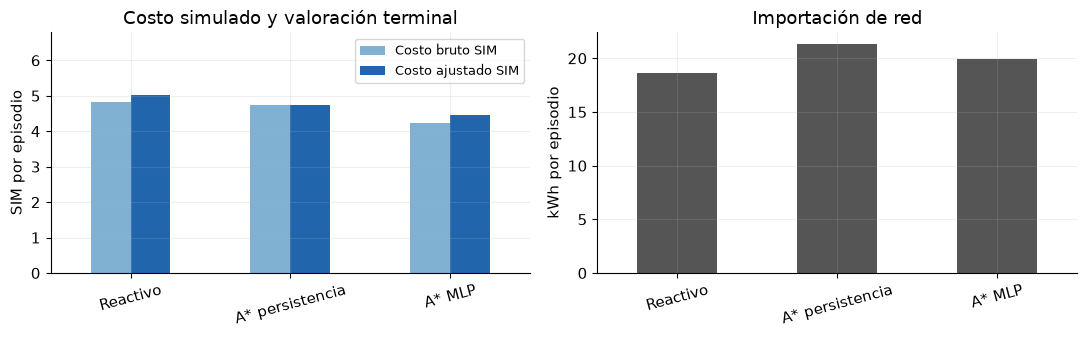

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(range(24), actual_demand, label="Consumo UCI", color="black")
axes[0].plot(range(24), solar[:24], label="Solar PVGIS independiente", color="#c47f00", ls="--")
axes[0].set(ylabel="kWh por hora", title="Episodio académico, perfiles independientes")
axes[0].legend()
styles = [("#555555", "-"), ("#b35806", "--"), ("#2166ac", "-.")]
for (label, ledger), (color, style) in zip(ledgers.items(), styles):
    axes[1].plot(range(25), np.r_[2.5, ledger.stored_kwh]/5*100, label=label, color=color, ls=style)
axes[1].axhline(20, color="black", lw=.8, ls=":", label="Piso físico")
axes[1].set(xlabel="Hora del escenario", ylabel="SOC (%)", ylim=(0, 105))
axes[1].legend(loc="upper center", bbox_to_anchor=(.5, -.24), ncol=2)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
energy_metrics[["Costo bruto SIM", "Costo ajustado SIM"]].plot.bar(ax=axes[0], rot=15, color=["#80b1d3", "#2166ac"])
axes[0].set(ylabel="SIM por episodio", xlabel="", title="Costo simulado y valoración terminal")
axes[0].set_ylim(0, 1.35*energy_metrics[["Costo bruto SIM", "Costo ajustado SIM"]].max().max())
axes[0].legend(loc="upper right", fontsize=9)
energy_metrics["Red kWh"].plot.bar(ax=axes[1], rot=15, color="#555555")
axes[1].set(ylabel="kWh por episodio", xlabel="", title="Importación de red")
fig.tight_layout(); plt.show()

## 7. Comprobaciones de métricas, búsqueda y causalidad
Verificamos una métrica calculable a mano, optimalidad en un grafo pequeño,
dependencia real de A* respecto al pronóstico y separación pasado/futuro.
Las aserciones de cada replay ya comprueban restricciones y conservación.

In [16]:
from functools import lru_cache
known = physical_metrics(np.array([0., 2.]), np.array([1., 4.]))
assert known["MAE kWh"] == 1.5 and np.isclose(known["RMSE kWh"], np.sqrt(2.5))
a, toy = plan([.3, .9, .4], [0., .1, 0.], [.08, .38, .15], .5, capacity=1.)
u, _ = plan([.3, .9, .4], [0., .1, 0.], [.08, .38, .15], .5, heuristic="zero", capacity=1.)
@lru_cache(None)
def enumerate_cost(state):
    if toy.is_goal(state): return 0.
    return min(edge + enumerate_cost(nxt) for _, nxt, edge in toy.successors(state))
assert np.isclose(a.value, u.value) and np.isclose(a.value, enumerate_cost(toy.initial))
low, _ = plan([0., 0.], [0., 0.], [.08, .38], .5, capacity=1.)
high, _ = plan([0., 1.], [0., 0.], [.08, .38], .5, capacity=1.)
assert low.actions[0] != high.actions[0]  # Cambiar pronóstico cambia decisión.
changed = hourly.copy()
changed.loc[changed.index >= origin, "load_kwh"] = 999.
np.testing.assert_array_equal(hourly.loc[hourly.index < origin].tail(168).load_kwh,
                              changed.loc[changed.index < origin].tail(168).load_kwh)
assert normalizer.fitted_hours == int(train.is_observed_complete.sum())
print("Comprobaciones aprobadas: métricas, A*/UCS/enumeración, integración predictiva, causalidad y física.")

Comprobaciones aprobadas: métricas, A*/UCS/enumeración, integración predictiva, causalidad y física.


## 8. Resultados y conclusión
La siguiente síntesis se genera desde las tablas de esta ejecución. No se
exige que MLP o A* ganen; pronosticar con menor RMSE tampoco garantiza mejores
decisiones energéticas. No se cambian parámetros al observar test.

In [17]:
test_rows = predictive_metrics[predictive_metrics.Partición == "Test académico"].set_index("Modelo")
neural_rmse = test_rows.loc["MLP", "RMSE kWh"]
baseline_rmse = test_rows.loc["Persistencia 24 h", "RMSE kWh"]
comparison = "menor" if neural_rmse < baseline_rmse else "mayor o igual"
display(Markdown(f"**Test académico:** RMSE MLP {neural_rmse:.4f} kWh frente a "
    f"{baseline_rmse:.4f} kWh de persistencia ({comparison})."))
display(Markdown(f"Se evaluaron **{len(w_test.x)} ventanas no solapadas de 24 h** "
    f"({len(w_test.x)*24} objetivos horarios) en test académico. Las ventanas "
    "con entradas desconocidas u objetivos no observados se excluyeron, sin rellenarlos con el futuro."))
for label in ("A* persistencia", "A* MLP"):
    delta = energy_metrics.loc[label, "Costo ajustado SIM"] - energy_metrics.loc["Reactivo", "Costo ajustado SIM"]
    display(Markdown(f"**{label}:** diferencia de costo ajustado frente a reactivo: {delta:+.4f} SIM "
                     "en este episodio simulado; el signo positivo indica mayor costo."))

**Test académico:** RMSE MLP 0.7687 kWh frente a 0.9700 kWh de persistencia (menor).

Se evaluaron **17 ventanas no solapadas de 24 h** (408 objetivos horarios) en test académico. Las ventanas con entradas desconocidas u objetivos no observados se excluyeron, sin rellenarlos con el futuro.

**A* persistencia:** diferencia de costo ajustado frente a reactivo: -0.2901 SIM en este episodio simulado; el signo positivo indica mayor costo.

**A* MLP:** diferencia de costo ajustado frente a reactivo: -0.5832 SIM en este episodio simulado; el signo positivo indica mayor costo.

### Registro pequeño de reproducibilidad
Se guardan tablas y arreglos de auditoría en el runtime, sin guardar pesos de
modelos. No hay pasos manuales ni archivos locales previos que preparar.

In [18]:
output = Path("bekantor_academic")
predictive_metrics.to_csv(output / "forecast_metrics.csv", index=False)
energy_metrics.to_csv(output / "energy_metrics.csv")
for label, ledger in ledgers.items():
    ledger.drop(columns="state").to_csv(output / (label.replace("*", "star").replace(" ", "_") + ".csv"), index=False)
np.savez_compressed(output / "audit_arrays.npz", val_actual=w_val.y, test_actual=w_test.y,
    val_mlp=predictions["Validación"]["MLP"], val_persistence=predictions["Validación"]["Persistencia 24 h"],
    test_mlp=predictions["Test académico"]["MLP"], test_persistence=predictions["Test académico"]["Persistencia 24 h"],
    episode_past=past_inputs, episode_actual=actual_demand, episode_solar=solar[:24],
    episode_mlp=causal_forecasts["A* MLP"], episode_persistence=causal_forecasts["A* persistencia"])
run_metadata = {"seed": SEED, "tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__,
    "cpu_only": not tf.config.get_visible_devices("GPU"), "epochs": len(history.history["loss"]),
    "training_seconds": training_seconds, "normalizer": asdict(normalizer),
    "episode_origin": origin.isoformat(), "model_selection_end": validation.index.max().isoformat(),
    "episode_partition": "academic_test", "academic_csv_sha256": digest(sample_bytes),
    "window_counts": {"train": len(w_train.x), "validation": len(w_val.x), "test": len(w_test.x)},
    "historical_test_used": False}
(output / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2), encoding="utf-8")
print("Tablas y auditoría guardadas en bekantor_academic/; no se guardaron modelos.")

Tablas y auditoría guardadas en bekantor_academic/; no se guardaron modelos.


**Conceptos relacionados, algoritmos distintos.** Adam optimiza pesos continuos
reduciendo MSE mediante gradientes de ejemplos históricos. A* busca una
secuencia de estados discretos minimizando costo energético con una red ya
congelada. La integración es efectiva: las 24 salidas previstas determinan
importaciones y costos de transición. A* no entrena la red ni utiliza gradientes.

**Límites:** muestra y semilla únicas, demanda sin calendario explícito,
distribución temporal cambiante, ventanas de evaluación limitadas, una sola
vivienda y episodio. La grilla pierde acciones posibles; solar ideal y tarifas
SIM no representan un contrato real. No se modelan degradación, límites de red,
cortes, resiliencia, hardware ni respuesta de usuarios. SOC alto por sí solo
no demuestra autonomía. UCI y PVGIS no están sincronizados. Esta entrega no
prueba ahorro real ni reutiliza el test histórico del MVP.

**Fuentes y método:** [UCI y licencia CC BY 4.0](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption),
[PVGIS/JRC](https://joint-research-centre.ec.europa.eu/photovoltaic-geographical-information-system-pvgis_en),
[aviso legal de reutilización UE](https://commission.europa.eu/legal-notice_en),
[TensorFlow CPU](https://www.tensorflow.org/install/pip),
[EarlyStopping](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping).
Los metadatos del notebook y `colab/assets/provenance.json` identifican las
fuentes, períodos, hashes y extracción de código. No requiere publicar nuevos
assets en GitHub para funcionar: UCI se descarga y el perfil solar está incluido.